# Reproducing Grokking

Paper: *Grokking: Generalization Beyond Overfitting on Small Algorithmic Datasets* (Power et al., 2022).

**Goal:** train a tiny transformer on clock math, `(a + b) mod 97`, and see the model first memorize, then much later "get" the rule.

**Before running:** in Colab, go to *Runtime → Change runtime type* and pick a **GPU** (a T4 is fine). It also works on CPU, just slower.

## 1. Setup

In [1]:
import random
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

Running on: cuda


## 2. Dataset

Every pair `a, b` from 0 to 96, with answer `(a + b) mod 97`. That's 9,409 equations.
We shuffle them randomly and use 50% for training and 50% for testing.

In [2]:
p = 97
TRAIN_FRACTION = 0.5          # try 0.3 or 0.4 later as an experiment

PLUS, EQ = p, p + 1           # symbol IDs for "+" and "="
VOCAB = p + 2                 # 97 numbers + "+" + "=" = 99 symbols

equations = [(a, b, (a + b) % p) for a in range(p) for b in range(p)]
random.shuffle(equations)

split = int(len(equations) * TRAIN_FRACTION)
train_eqs, test_eqs = equations[:split], equations[split:]

def to_tensors(eqs):
    X = torch.tensor([[a, PLUS, b, EQ] for a, b, c in eqs])
    Y = torch.tensor([c for a, b, c in eqs])
    return X.to(device), Y.to(device)

train_X, train_Y = to_tensors(train_eqs)
test_X, test_Y = to_tensors(test_eqs)

print("Train:", len(train_eqs), "Test:", len(test_eqs))
print("Example input:", train_X[0].tolist(), "-> answer:", train_Y[0].item())

Train: 4704 Test: 4705
Example input: [73, 97, 93, 98] -> answer: 69


## 3. Model

A small transformer: 2 layers, width 128, 4 attention heads (same as the paper).
It reads `[a, +, b, =]` and gives 97 scores, one per possible answer.

In [11]:
class GrokModel(nn.Module):
    def __init__(self, d=128, heads=4, layers=2, seq_len=4):
        super().__init__()
        self.tok = nn.Embedding(VOCAB, d)      # symbol -> 128 numbers
        self.pos = nn.Embedding(seq_len, d)    # position -> 128 numbers
        layer = nn.TransformerEncoderLayer(
            d, heads, dim_feedforward=4 * d,
            dropout=0.0, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers)
        self.out = nn.Linear(d, p)             # 128 numbers -> 97 scores

    def forward(self, x):                      # x: (batch, 4)
        positions = torch.arange(x.shape[1], device=x.device)
        h = self.tok(x) + self.pos(positions)
        mask = nn.Transformer.generate_square_subsequent_mask(
            x.shape[1], device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)
        return self.out(h[:, -1])              # scores from the "=" position

model = GrokModel().to(device)
print("Parameters:", sum(t.numel() for t in model.parameters()))

Parameters: 422241


## 4. Training

Settings from the paper: AdamW, learning rate 0.001, **weight decay 1**, betas (0.9, 0.98),
warmup over the first 10 steps, batch size 512.

Every 100 steps we check accuracy on both the training set and the hidden test set.

In [12]:
STEPS = 20000
BATCH = min(512, len(train_eqs) // 2)
EVAL_EVERY = 100

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3,
                              weight_decay=0.1, betas=(0.9, 0.98))
warmup = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1.0, (s + 1) / 10))
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def accuracy(X, Y):
    model.eval()
    acc = (model(X).argmax(dim=-1) == Y).float().mean().item()
    model.train()
    return acc

log = {"step": [], "train_acc": [], "test_acc": []}

for step in range(1, STEPS + 1):
    idx = torch.randint(0, len(train_X), (BATCH,), device=device)
    loss = loss_fn(model(train_X[idx]), train_Y[idx])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    warmup.step()

    if step % EVAL_EVERY == 0:
        tr, te = accuracy(train_X, train_Y), accuracy(test_X, test_Y)
        log["step"].append(step); log["train_acc"].append(tr); log["test_acc"].append(te)
        if step % 1000 == 0:
            print(f"step {step:6d} | train {tr:6.1%} | test {te:6.1%}")

step   1000 | train 100.0% | test   1.3%
step   2000 | train  99.9% | test   2.8%
step   3000 | train  99.9% | test   5.8%
step   4000 | train  99.8% | test  13.7%
step   5000 | train  99.9% | test  35.0%
step   6000 | train 100.0% | test  59.4%
step   7000 | train 100.0% | test  66.9%
step   8000 | train 100.0% | test  79.6%
step   9000 | train 100.0% | test  92.6%
step  10000 | train 100.0% | test  98.0%
step  11000 | train 100.0% | test  99.6%
step  12000 | train 100.0% | test 100.0%
step  13000 | train 100.0% | test 100.0%
step  14000 | train 100.0% | test 100.0%
step  15000 | train 100.0% | test  99.1%
step  16000 | train  99.9% | test  99.1%
step  17000 | train 100.0% | test 100.0%
step  18000 | train 100.0% | test 100.0%
step  19000 | train 100.0% | test 100.0%
step  20000 | train 100.0% | test 100.0%


## 5. The grokking chart

Success looks like: the training line reaches 100% early, the test line stays low for a while, then jumps up.
The x-axis uses a log scale so the jump is easy to see.

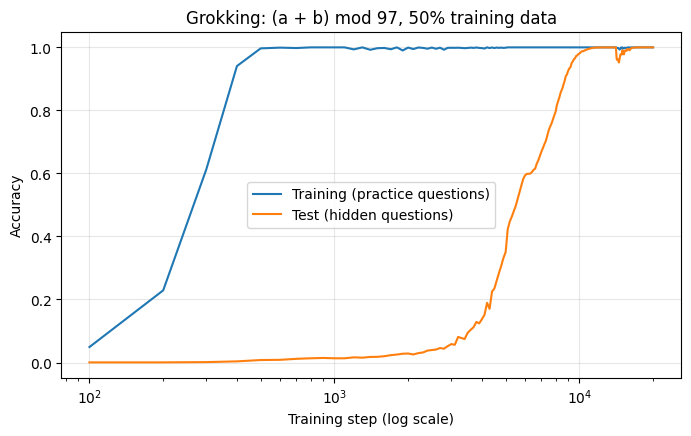

Training hit 99% at step: 500
Test hit 99% at step:     10500


In [13]:
plt.figure(figsize=(8, 4.5))
plt.plot(log["step"], log["train_acc"], label="Training (practice questions)")
plt.plot(log["step"], log["test_acc"], label="Test (hidden questions)")
plt.xscale("log")
plt.xlabel("Training step (log scale)")
plt.ylabel("Accuracy")
plt.title("Grokking: (a + b) mod 97, 50% training data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

def first_step_above(accs, level=0.99):
    for s, a in zip(log["step"], accs):
        if a >= level:
            return s
    return None

print("Training hit 99% at step:", first_step_above(log["train_acc"]))
print("Test hit 99% at step:    ", first_step_above(log["test_acc"]))

## 6. Look for the circle

We take the learned 128-number list for each of the 97 numbers and squash it to 2 numbers with **PCA**, then plot it.
Left: the input embeddings. Right: the output layer (what the paper drew).

The model actually uses a few circles at different "speeds", so the top 2 PCA directions may show a clean ring, or a messier shape. Both are normal.

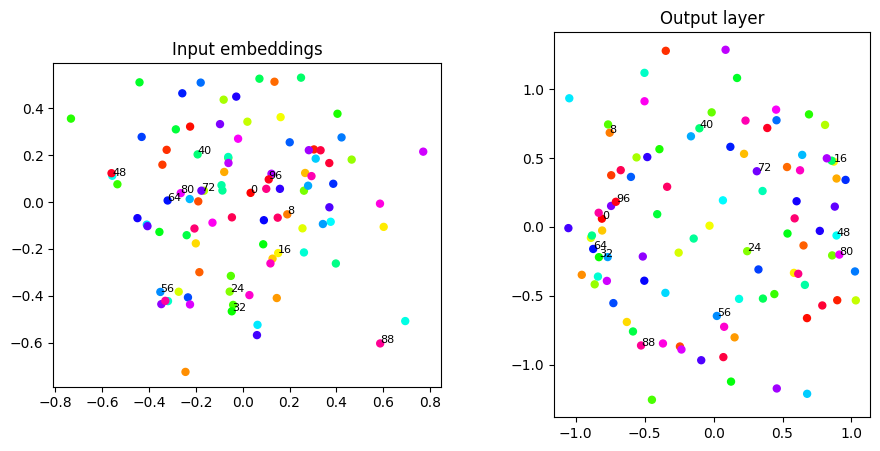

In [14]:
from sklearn.decomposition import PCA

tables = {
    "Input embeddings": model.tok.weight[:p].detach().cpu().numpy(),
    "Output layer": model.out.weight.detach().cpu().numpy(),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, W) in zip(axes, tables.items()):
    pts = PCA(n_components=2).fit_transform(W)
    ax.scatter(pts[:, 0], pts[:, 1], c=range(p), cmap="hsv", s=25)
    for n in range(0, p, 8):
        ax.annotate(str(n), pts[n], fontsize=8)
    ax.set_title(name)
    ax.set_aspect("equal")
plt.show()

## 7. Next experiments (change one thing at a time)

- `TRAIN_FRACTION = 0.3` → does the wait get longer?
- `weight_decay=0.1` or `0.0` → does grokking slow down or disappear?
- Change the answer to `(a - b) % p` → does subtraction need more steps?

Keep a note of each run's settings and the step where the test line hits 99%.